# 01 · Raw data inspection and cleaning (House 1)

**Data:** raw REFIT, House 1 only. **Goal:** a documented, re-runnable cleaning pipeline that resamples to 1-minute resolution.

All logic lives in `src/preprocessing.py`, so this notebook can be re-run from scratch. Every number below is computed from the files on disk.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src import config as cfg
from src import visualization as viz

viz.apply_style()
pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_colwidth", 70)
for folder in (cfg.FIGURES, cfg.METRICS, cfg.PREDICTIONS):
    folder.mkdir(parents=True, exist_ok=True)

from src.data_loader import load_raw_part, parse_readme, read_clean_csv
from src import preprocessing as pp
import matplotlib.dates as mdates

## 1. Inspect the raw files

In [2]:
part1, part2 = load_raw_part(1), load_raw_part(2)
print("Part 1 shape:", part1.shape, "| Part 2 shape:", part2.shape)
print("Columns:", list(part1.columns))
display(pd.DataFrame({"Part 1 dtype": part1.dtypes, "Part 2 dtype": part2.dtypes}))
display(part1.head(3))
display(part2.head(3))
print("README channel list for House 1:")
for channel, description in parse_readme()[1].items():
    print(f"  {channel}: {description}")

Part 1 shape: (4377877, 12) | Part 2 shape: (4140886, 12)
Columns: ['Time', 'Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9']


,Part 1 dtype,Part 2 dtype
Time,object,object
Unix,int64,int64
Aggregate,int64,float64
Appliance1,int64,float64
Appliance2,int64,float64
Appliance3,int64,float64
Appliance4,int64,float64
Appliance5,int64,float64
Appliance6,int64,float64
Appliance7,int64,float64


,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2013-10-09 14:06:17,1381327577,523,74,0,69,0,0,0,0,0,1
1,2013-10-09 14:06:31,1381327591,526,75,0,69,0,0,0,0,0,1
2,2013-10-09 14:06:46,1381327606,540,74,0,68,0,0,0,0,0,1


,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2014-06-27 21:57:50,1403906269,322.0,0.0,0.0,72.0,0.0,0.0,0.0,0.0,NaN,NaN
1,2014-06-27 21:57:51,1403906271,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.0,1.0
2,2014-06-27 21:57:58,1403906278,329.0,NaN,0.0,NaN,NaN,0.0,0.0,0.0,30.0,NaN


README channel list for House 1:
  0: Aggregate
  1: Fridge, Hotpoint, RLA50P
  2: Freezer(1),Beko, CF393APW
  3: Freezer(2), Unknown, Unknown
  4: Washer Dryer, Creda, T522VW
  5: Washing Machine, Beko, WMC6140
  6: Dishwasher, Bosch, Unknown
  7: Computer, Lenovo, H520s
  8: Television Site, Toshiba, 32BL502b
  9: Electric Heater, GLEN, 2172


**What this shows.** There are 8,518,763 raw rows in two files with 12 columns. Part 1 runs from 9 Oct 2013 to 1 Oct 2014 and stores integers with no missing values. Part 2 runs from 27 Jun 2014 to 10 Jul 2015 and stores floats with missing values. The two files overlap by about three months.

The README says Part 1 wrote unavailable sensors as 0 and Part 2 writes them as NaN. **So a zero in Part 1 does not prove the appliance was off.**

The aggregate is measured directly by a current clamp, and it is not the sum of the channels. The nine appliance monitors cover only some of the home's loads, and the REFIT authors report that they are not synchronised with the clamp (Murray et al., 2017). Channels 1 and 2 (fridge and freezer) are used for the before-and-after charts because they run constantly, so changes are easy to see.

## 2. Data-quality report (before any change)

In [3]:
quality = pd.concat([pp.raw_quality_report(part1, "Part 1"), pp.raw_quality_report(part2, "Part 2")], axis=1)
quality.to_csv(cfg.METRICS / "raw_house1_quality_report.csv")
display(quality)

missing = pd.DataFrame({
    "Part 1 missing %": part1[pp.CHANNELS].isna().mean() * 100,
    "Part 2 missing %": part2[pp.CHANNELS].isna().mean() * 100,
    "Part 1 zero %": (part1[pp.CHANNELS] == 0).mean() * 100,
    "Part 2 zero %": (part2[pp.CHANNELS] == 0).mean() * 100,
}).round(2)
missing.to_csv(cfg.METRICS / "raw_house1_missingness_by_channel.csv")
display(missing)

,Part 1,Part 2
Check,,
Total records,4377877,4140886
Unparseable Time values,0,0
Start (raw clock),2013-10-09 14:06:17,2014-06-27 21:57:50
End (raw clock),2014-10-01 01:27:07,2015-07-10 11:56:32
Backward time steps,1,0
Duplicate Unix timestamps,1004404,14755
Exact duplicate rows,595935,0
Duplicate timestamps with different aggregate,79519,126
"Missing values, all channels",0,5284083


,Part 1 missing %,Part 2 missing %,Part 1 zero %,Part 2 zero %
Aggregate,0.0,4.56,0.00,0.00
Appliance1,0.0,10.57,75.97,68.08
Appliance2,0.0,11.10,63.58,58.02
Appliance3,0.0,7.53,59.95,54.16
Appliance4,0.0,12.34,99.27,87.55
Appliance5,0.0,12.01,97.87,85.95
Appliance6,0.0,8.27,99.08,90.88
Appliance7,0.0,5.62,90.70,82.77
Appliance8,0.0,9.44,81.04,73.45
Appliance9,0.0,46.17,0.02,0.02


**What this shows, and why each issue matters.**

- **Sampling:** the median interval is 7 s, not the 8 s the README states. Gaps longer than 2 minutes number 593 in Part 1 and 122 in Part 2. Long gaps matter because treating them as zero would understate energy.
- **Duplicates:** Part 1 has 1,004,404 duplicate timestamps, of which 595,935 rows are exact copies. Left alone, these would give repeated seconds extra weight in a minute's average.
- **Missing values:** Part 1 shows 0 only because it stored missing data as 0. Part 2's 5,284,083 missing values mostly mean "unchanged", because the system logs on change.
- **Negative readings:** none. There is nothing to fix.
- **Extreme values:** aggregate readings reach 29,159 W and appliance readings reach 98,301 W. Both need investigating (section 3d).
- **Zeros:** 12 aggregate readings are exactly 0 W, which is implausible for an occupied home with always-on appliances.

## 3. Investigating what the report found

### 3a. Is `Unix` really UTC? The clock

`Time` and `Unix` describe the same clock (apart from one-second rounding), and `Unix` steps backward once. A true Unix timestamp can never do that.

In [4]:
unix = part1["Unix"].to_numpy()
back = np.flatnonzero(np.diff(unix) < -60)
print("Backward steps over 60 s in Part 1:", [(part1["Time"].iloc[i], part1["Time"].iloc[i + 1], int(unix[i + 1] - unix[i])) for i in back])
gap_at_spring = part1[(part1["Time"] >= "2014-03-30 00:59:00") & (part1["Time"] < "2014-03-30 02:01:00")]
print("Spring 2014 clock change, largest step in Part 1 (s):", int(gap_at_spring["Unix"].diff().max()), "at", gap_at_spring.loc[gap_at_spring["Unix"].diff().idxmax(), "Time"])
rows_per_hour = pd.to_datetime(part2["Time"]).dt.floor("h").value_counts()
print("Part 2 rows per hour around 26 Oct 2014 (the 01:00 hour happens twice, interleaved):")
print(rows_per_hour.reindex(pd.date_range("2014-10-26 00:00", "2014-10-26 03:00", freq="1h")).to_string())

Backward steps over 60 s in Part 1: [('2013-10-27 01:59:59', '2013-10-27 01:00:01', -3597)]


Spring 2014 clock change, largest step in Part 1 (s): 3605 at 2014-03-30 02:00:02


Part 2 rows per hour around 26 Oct 2014 (the 01:00 hour happens twice, interleaved):
2014-10-26 00:00:00    534
2014-10-26 01:00:00    986
2014-10-26 02:00:00    535
2014-10-26 03:00:00    534
Freq: h


**The raw `Unix` column is not true Unix time.** It jumps back 3,597 s at 27 Oct 2013 01:59:59 and forward 3,605 s at 30 Mar 2014 02:00, exactly when UK clocks change. It is UK wall-clock time written as seconds. This matters because sorting by it scrambles an hour every autumn, and treating it as UTC shifts half the year by an hour.

In Part 1 the file order reveals which repeat of the hour a row belongs to, so that hour can be recovered. Part 2 was exported sorted, so the 986 rows in the repeated hour of 26 Oct 2014 cannot be separated, and they are dropped.

### 3b. Duplicate timestamps

In [5]:
dups = part1[part1["Unix"].duplicated(keep=False)]
display(dups.head(6))
conflicts = dups.groupby("Unix")["Aggregate"].agg(lambda s: s.max() - s.min())
conflicts = conflicts[conflicts > 0]
print(f"Timestamps with conflicting aggregate readings: {len(conflicts):,} of {dups['Unix'].nunique():,}")
print("Size of the conflict (W):", conflicts.describe().round(1).to_dict())

,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
18,2013-10-09 14:08:45,1381327725,628,73,0,0,0,0,0,0,0,1
19,2013-10-09 14:08:46,1381327725,628,73,0,0,0,0,0,0,0,1
83,2013-10-09 14:15:16,1381328116,1392,70,0,0,0,0,0,0,0,1
84,2013-10-09 14:15:17,1381328116,1392,70,0,0,0,0,0,0,0,1
92,2013-10-09 14:16:14,1381328174,1338,70,0,0,0,0,0,0,0,1
93,2013-10-09 14:16:15,1381328174,1338,70,0,0,0,0,0,0,0,1


Timestamps with conflicting aggregate readings: 79,519 of 829,193
Size of the conflict (W): {'count': 79519.0, 'mean': 38.5, 'std': 277.0, 'min': 1.0, '25%': 1.0, '50%': 3.0, '75%': 6.0, 'max': 10474.0}


**Rule: keep the last non-null reading of each channel for that second.** Most duplicates are harmless: 829,193 timestamps repeat, and only 79,519 of them disagree on the aggregate, with a median difference of 3 W. Keeping the later row assumes it is the newer poll, which file order supports but cannot prove. A few differ by up to 10,474 W. The close match with the official file in section 6 suggests the rule causes little harm.

### 3c. The Part 1 / Part 2 overlap

The two files overlap in time. Which should we trust? We compare each with the official cleaned file. The official file is used **only as a check**, not as a source of values.

In [6]:
official = read_clean_csv(1, ["Unix", "Aggregate"]).rename(columns={"Unix": "U", "Aggregate": "official"})
p1_sorted = part1[["Unix", "Aggregate"]].drop_duplicates("Unix").sort_values("Unix")
p2_sorted = part2[["Unix", "Aggregate"]].dropna().drop_duplicates("Unix")
rows = []
for start in pd.date_range("2014-07-01", "2014-09-22", freq="14D"):
    low, high = int(start.timestamp()), int((start + pd.Timedelta(days=3)).timestamp())
    row = {"3 days from": start.date()}
    for name, table in (("Part 1", p1_sorted), ("Part 2", p2_sorted)):
        chunk = table[(table["Unix"] >= low) & (table["Unix"] < high)]
        # Official rows before 1 Oct 2014 sit 3600 s earlier than the raw clock in summer.
        matched = pd.merge_asof(chunk.assign(U=chunk["Unix"] - 3600), official, on="U", direction="nearest", tolerance=8)
        row[f"{name} vs official MAE (W)"] = round((matched["Aggregate"] - matched["official"]).abs().mean(), 1)
    rows.append(row)
overlap = pd.DataFrame(rows)
overlap.to_csv(cfg.METRICS / "raw_house1_overlap_check.csv", index=False)
display(overlap)

,3 days from,Part 1 vs official MAE (W),Part 2 vs official MAE (W)
0,2014-07-01,0.4,17.0
1,2014-07-15,0.8,61.2
2,2014-07-29,0.8,129.5
3,2014-08-12,1.2,96.5
4,2014-08-26,0.4,119.2
5,2014-09-09,0.4,26.6


**Part 1 is kept in the overlap.** It matches the official cleaned file to within 0.4-1.2 W, while Part 2 differs by 17-129.5 W. That indicates the publishers built this period from Part 1. Part 2 rows in the overlap (945,403) are dropped, which also avoids counting these months twice. The official file is used here only to choose between the sources.

### 3d. Extreme readings: investigate before removing

In [7]:
counts, values = {}, []
for channel in cfg.APPLIANCES:
    for part in (part1, part2):
        column = part[channel].to_numpy(dtype=float)
        hits = column[column > cfg.APPLIANCE_MAX_W]
        counts[channel] = counts.get(channel, 0) + len(hits)
        values.append(hits)
extreme = pd.Series(np.concatenate(values))
print(f"Appliance readings above {cfg.APPLIANCE_MAX_W} W: {len(extreme):,}")
print("Most common extreme values (W):", extreme.value_counts().head(10).to_dict())
print("By channel:", counts)
total = len(part1) * 9 + part2[cfg.APPLIANCES].notna().sum().sum()
print(f"Share of all appliance readings: {100 * len(extreme) / total:.4f}%")

high_days, high_values, longest = set(), [], 0
for part in (part1, part2):
    above = part["Aggregate"].to_numpy(dtype=float) > 15000
    high_values.append(part.loc[above, "Aggregate"])
    high_days.update(pd.to_datetime(part.loc[above, "Time"]).dt.date)
    run_ids = np.cumsum(~above)
    if above.any():
        longest = max(longest, int(np.bincount(run_ids[above]).max()))
high = pd.concat(high_values)
print(f"\nAggregate above 15 kW: {len(high):,} rows on {len(high_days)} days")
print(high.describe().round(0).to_dict())
print("Longest run above 15 kW (consecutive rows):", longest)

Appliance readings above 4000 W: 3,949
Most common extreme values (W): {8192.0: 1291, 4096.0: 1073, 4160.0: 448, 16384.0: 182, 4169.0: 100, 98301.0: 95, 5120.0: 74, 32767.0: 65, 10240.0: 34, 8193.0: 26}
By channel: {'Appliance1': 846, 'Appliance2': 40, 'Appliance3': 118, 'Appliance4': 2085, 'Appliance5': 221, 'Appliance6': 36, 'Appliance7': 374, 'Appliance8': 179, 'Appliance9': 50}


Share of all appliance readings: 0.0055%

Aggregate above 15 kW: 186 rows on 17 days
{'count': 186.0, 'mean': 21351.0, 'std': 3089.0, 'min': 15043.0, '25%': 18225.0, '50%': 22350.0, '75%': 24000.0, 'max': 29159.0}
Longest run above 15 kW (consecutive rows): 18


**The spikes are sensor errors, not real loads.** The most common extreme appliance values are 8192, 4096, 16384 and 32767, which are powers of two or a 16-bit limit. Real power does not cluster on those numbers. They make up 0.0055% of appliance readings, so masking them above the REFIT authors' 4,000 W limit costs almost nothing.

The aggregate needs more care. Readings above 15 kW occur in 186 rows on 17 days, and the longest run is 18 rows, about 2 minutes. Readings above 23,000 W (100 A x 230 V, the largest common UK domestic fuse) are masked. Those between 15 and 23 kW are kept, because I cannot prove they are wrong.

## 4. Run the cleaning pipeline

Order of operations:

1. Convert to one true-UTC clock.
2. Resolve the Part 1 / Part 2 overlap.
3. Merge duplicate timestamps.
4. Set impossible values to missing.
5. Hold change-only readings for up to 2 minutes.
6. Mask frozen aggregate readings.
7. Average to 1 minute.
8. Interpolate only gaps of 5 minutes or less, flagging each one, and leave longer outages empty.

In [8]:
saved_path = cfg.DATA_PROCESSED / "house1_raw_cleaned_1min.parquet"
already_saved = saved_path.exists()
cleaned, audit = pp.clean_raw_house1(part1, part2, save=not already_saved)
if already_saved:  # never overwrite an existing table; confirm this run reproduces it instead
    pd.testing.assert_frame_equal(cleaned, pd.read_parquet(saved_path), check_freq=False)
    print("This run reproduces the saved table exactly, so it was left untouched.")
audit.to_csv(cfg.METRICS / "raw_house1_cleaning_audit.csv")
display(audit)
print("Cleaned table:", saved_path.relative_to(ROOT).as_posix())
print("Coverage (UTC):", cleaned.index[0], "to", cleaned.index[-1])
print(f"Aggregate available: {100 * cleaned['Aggregate'].notna().mean():.2f}% of minutes")
display(cleaned[pp.CHANNELS].describe().T[["count", "min", "50%", "max"]].round(1))

gap = cleaned["Aggregate"].isna() | cleaned["Aggregate_imputed"]
lengths = gap.groupby((gap != gap.shift()).cumsum()).sum()
lengths = lengths[lengths > 0]
bands = pd.cut(lengths, [0, 2, 5, 15, 60, 24 * 60, 10**7], labels=["1-2 min", "3-5 min", "6-15 min", "16-60 min", "1-24 h", "over 24 h"])
gap_table = pd.DataFrame({"Gaps": lengths.groupby(bands, observed=False).size(), "Minutes lost": lengths.groupby(bands, observed=False).sum()})
gap_table["Action"] = ["Interpolated", "Interpolated", "Left empty", "Left empty", "Left empty", "Left empty"]
gap_table.to_csv(cfg.METRICS / "raw_house1_gap_lengths.csv")
display(gap_table)

This run reproduces the saved table exactly, so it was left untouched.


,Count
Step,
Rows read (Part 1 + Part 2),8518763
Dropped: unresolvable repeated clock hour,986
Dropped: Part 2 rows inside the overlap with Part 1,945403
Merged: rows sharing a timestamp,1016005
Set missing: negative readings,0
Set missing: aggregate exactly 0 W (a home always has some load),8
Set missing: aggregate above 23000 W,59
Set missing: appliance above 4000 W,3228
Sensor readings held forward (2 min limit),2255728


Cleaned table: data/processed/house1_raw_cleaned_1min.parquet
Coverage (UTC): 2013-10-09 13:06:00 to 2015-07-10 10:56:00
Aggregate available: 86.69% of minutes


,count,min,50%,max
Aggregate,797585.0,113.5,245.9,22748.1
Appliance1,797813.0,0.0,0.0,3072.0
Appliance2,797155.0,0.0,0.0,2099.0
Appliance3,797242.0,0.0,0.0,585.1
Appliance4,798367.0,0.0,0.0,2688.9
Appliance5,793503.0,0.0,0.0,2461.8
Appliance6,798568.0,0.0,0.0,2378.5
Appliance7,798626.0,0.0,0.0,2049.0
Appliance8,797931.0,0.0,0.0,1194.7
Appliance9,708995.0,0.0,1.0,2085.3


,Gaps,Minutes lost,Action
1-2 min,366,475,Interpolated
3-5 min,77,280,Interpolated
6-15 min,342,3932,Left empty
16-60 min,44,1274,Left empty
1-24 h,20,5088,Left empty
over 24 h,12,112152,Left empty


**How to read the chart below.** Each row is a channel and each column a day, with paler shades meaning less data. The large pale block is the February 2014 outage the README mentions, and it affects every channel at once, which points to the data logger and not the sensors. Appliance 9 also loses a block from about October to December 2014 while other channels continue, so outages can be specific to one sensor. Gaps over 24 hours hold almost all of the lost minutes, so gap filling can never recover them, and it should not try to.

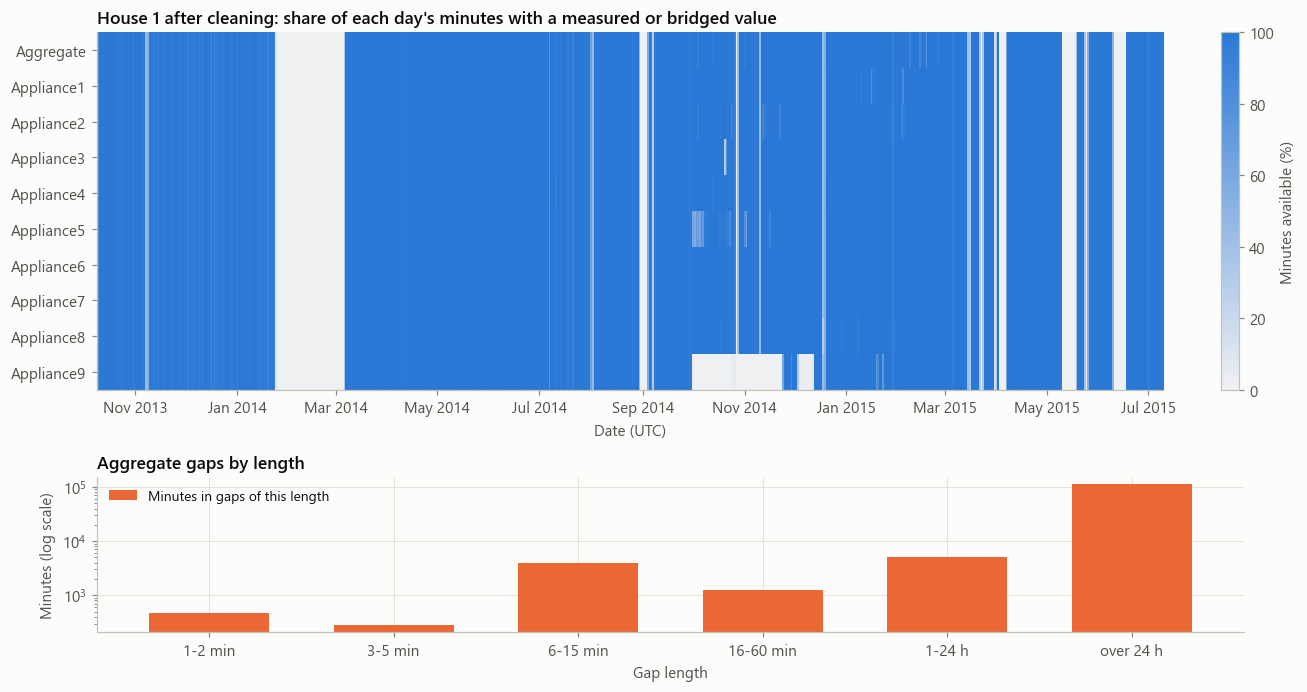

In [9]:
daily = cleaned[pp.CHANNELS].notna().resample("1D").mean() * 100
fig, axes = plt.subplots(2, 1, figsize=(12, 6.4), gridspec_kw={"height_ratios": [3, 1.3]})
image = axes[0].imshow(daily.T.values, aspect="auto", cmap=sns.light_palette(viz.BLUE, as_cmap=True), vmin=0, vmax=100, interpolation="nearest",
                       extent=[mdates.date2num(daily.index[0]), mdates.date2num(daily.index[-1]), len(pp.CHANNELS), 0])
axes[0].xaxis_date()
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axes[0].set_yticks(np.arange(len(pp.CHANNELS)) + 0.5, pp.CHANNELS)
axes[0].grid(False)
axes[0].set_title("House 1 after cleaning: share of each day's minutes with a measured or bridged value")
axes[0].set_xlabel("Date (UTC)")
fig.colorbar(image, ax=axes[0], label="Minutes available (%)", fraction=0.02)
axes[1].bar(gap_table.index.astype(str), gap_table["Minutes lost"], color=viz.ORANGE, width=0.65, label="Minutes in gaps of this length")
axes[1].set_yscale("log")
axes[1].set_title("Aggregate gaps by length")
axes[1].set_xlabel("Gap length")
axes[1].set_ylabel("Minutes (log scale)")
axes[1].legend(loc="upper left")
fig.tight_layout()
viz.save(fig, "01_missingness_gaps")
plt.show()

**What the pipeline did.** Of 920,031 study minutes, 86.69% have an aggregate value. Twelve gaps over 24 hours account for 112,152 of the 123,201 empty minutes (91%).

**Why a 5-minute limit for interpolation.** With readings every 7 s, a 5-minute gap is about 40 consecutive readings lost, and over that short a time a straight line is a fair guess at the average load. It affects only 755 minutes, 0.6% of the empty total, so the result barely depends on the exact limit. Each one is flagged in a `_imputed` column. Longer gaps stay empty and are flagged in `aggregate_outage`.

**Why the mean.** Mean power over a minute multiplied by the time gives the energy used in that minute. A median or last-value sample would not preserve energy.

**Zero versus missing.** A real zero stays 0. Missing stays NaN. Nothing missing is ever converted to zero, and impossible values become NaN, not zero.

## 5. Before and after

The left panels show the whole study as hourly maxima, which is where spikes and outages stand out. The right panels zoom in on the day with that channel's worst raw reading. **The y-axes differ on purpose:** with a shared axis, the spikes would flatten the cleaned signal into a line.

Aggregate: largest raw reading 29,159 W on 2014-10-21; largest cleaned 1-minute value 22,748 W


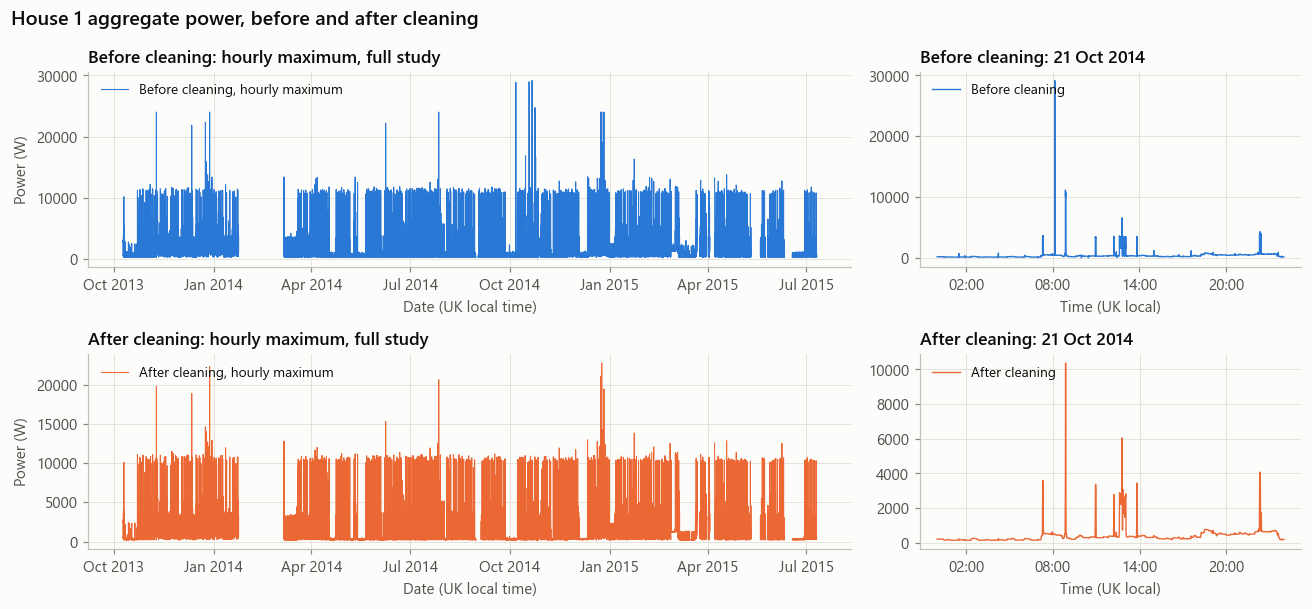

In [10]:
def compare(channel, title, name, description):
    raw_series = pd.concat([
        pd.Series(part1[channel].to_numpy(float), index=pd.to_datetime(part1["Unix"], unit="s")),
        pd.Series(part2[channel].to_numpy(float), index=pd.to_datetime(part2["Unix"], unit="s")),
    ]).dropna().sort_index()
    after = pd.Series(cleaned[channel].to_numpy(), index=pd.DatetimeIndex(cleaned["local_time"]))
    worst_day = raw_series.idxmax().normalize()
    print(f"{description}: largest raw reading {raw_series.max():,.0f} W on {worst_day.date()}; largest cleaned 1-minute value {after.max():,.0f} W")
    return viz.before_after(raw_series, after, title, name, worst_day)

compare("Aggregate", "House 1 aggregate power, before and after cleaning", "01_aggregate_before_after", "Aggregate")
plt.show()

**What changed.** The highest readings are gone, including the 29,159 W peak on 21 Oct 2014, and the study's outages stay visible as empty spans. The band up to about 11 kW is untouched, because it recurs throughout the study and looks like a real large load. An electric shower is one possibility, but no channel records it, so that is not confirmed.

**Remaining concern:** the largest cleaned minute is still 22,748 W, which is below the limit but unusual.

Appliance 1: largest raw reading 76,677 W on 2015-02-27; largest cleaned 1-minute value 3,072 W


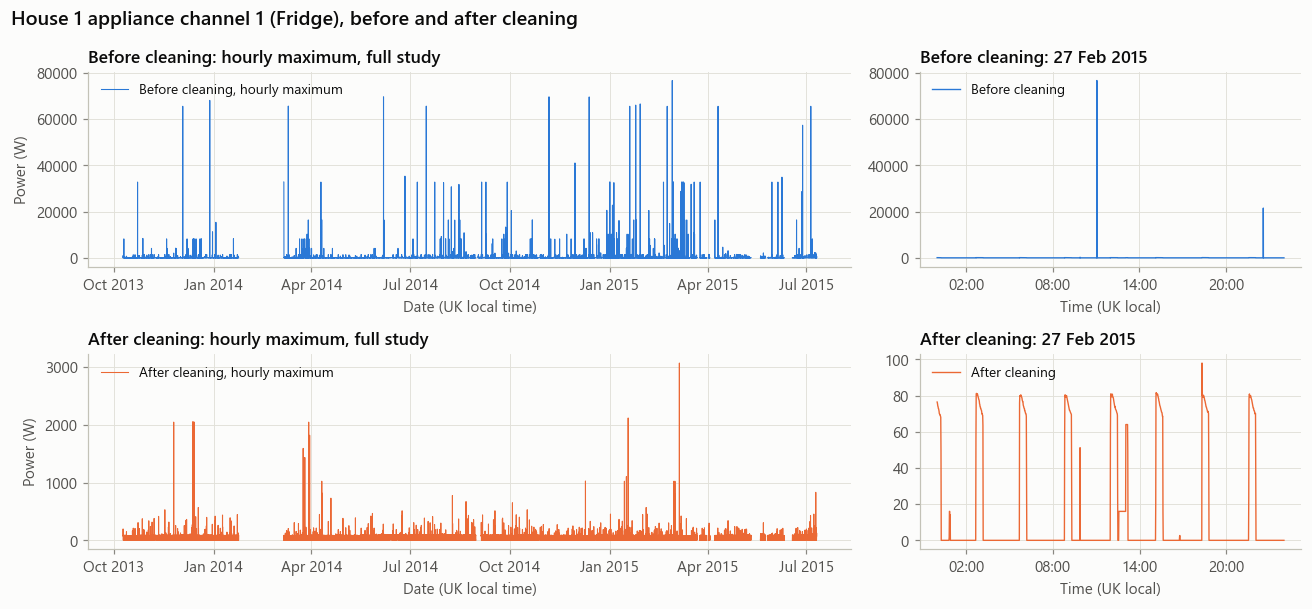

In [11]:
names = parse_readme()[1]
compare("Appliance1", f"House 1 appliance channel 1 ({names[1].split(',')[0]}), before and after cleaning", "01_appliance1_before_after", "Appliance 1")
plt.show()

Appliance 2: largest raw reading 98,301 W on 2013-12-23; largest cleaned 1-minute value 2,099 W


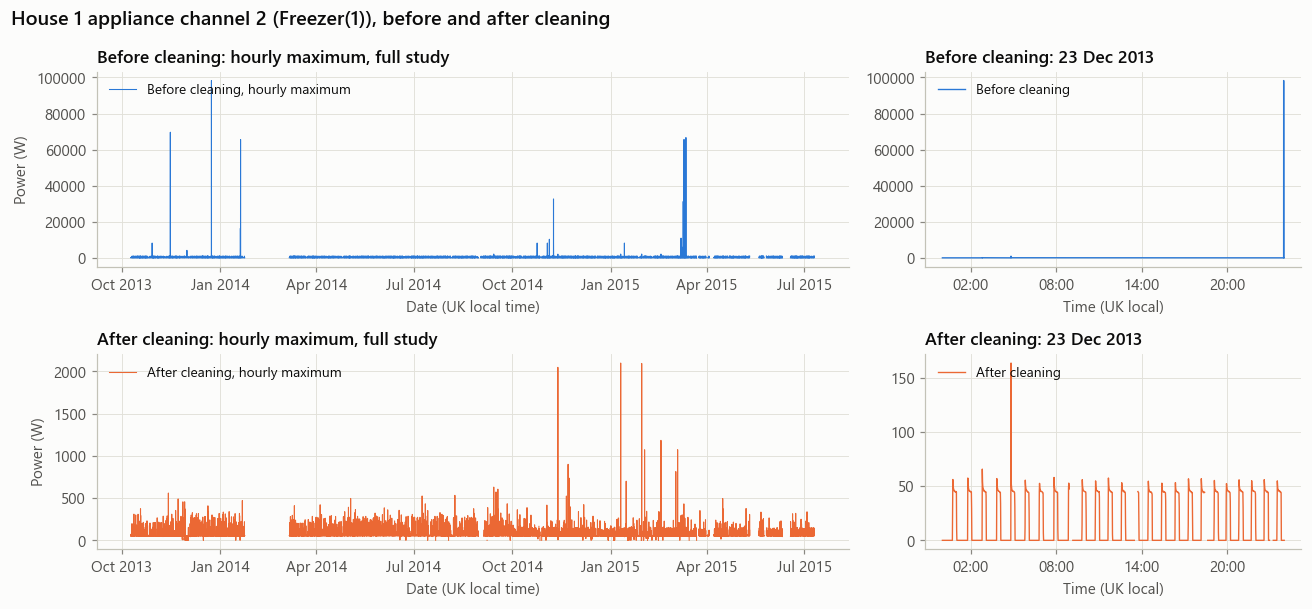

In [12]:
compare("Appliance2", f"House 1 appliance channel 2 ({names[2].split(',')[0]}), before and after cleaning", "01_appliance2_before_after", "Appliance 2")
plt.show()

**What changed.** The fridge's largest raw reading of 76,677 W and the freezer's 98,301 W are removed. The ordinary on-off cycling is unchanged.

**Remaining concern, found while checking this result:** the fridge's largest cleaned 1-minute value is still 3,072 W and the freezer's is 2,099 W. Neither is plausible for that appliance, and 3,072 is 2048 + 1024, the same bit-level pattern. So a single 4,000 W limit lets smaller glitches through. A limit for each appliance would catch these. It has not been applied, because these channels are not used in the model and notebook 02 measures how much of this survives on the washing-machine channels.

## 6. Consistency check against the official cleaned file

The pipeline code does not read the official cleaned values when it cleans, but the official file did inform two design decisions: choosing Part 1 in the overlap, and working out the clock. So this is a consistency check, not an independent test. Benchmarks with no cleaning show how much the headline agreement can actually tell us. All versions are compared on the same corrected clock.

In [13]:
# Benchmarks with no cleaning, on the same corrected clock, built before the raw files are freed.
from src.data_loader import wm_channel

WASHER = f"Appliance{wm_channel(1)}"
keep = ["utc", "Aggregate", WASHER]
naive_p1 = part1.assign(utc=pp.raw_true_utc(part1, 1))[keep].dropna(subset=["utc"])
naive_p2 = part2.assign(utc=pp.raw_true_utc(part2, 2))[keep].dropna(subset=["utc"])
naive_versions = {
    "Naive: all merged, no masking": pd.concat([naive_p1, naive_p2]).set_index("utc").sort_index().resample("1min").mean(),
    "Naive: Part 1 priority, no masking": pd.concat([naive_p1, naive_p2[naive_p2["utc"] > naive_p1["utc"].max()]]).set_index("utc").sort_index().resample("1min").mean(),
}
del naive_p1, naive_p2
print("Washing-machine channel in House 1:", WASHER)

Washing-machine channel in House 1: Appliance5


In [14]:
del part1, part2
import gc
gc.collect()
official = read_clean_csv(1, ["Unix", "Time", *pp.CHANNELS])
official["utc"] = pp.clean_file_true_utc(official["Unix"])
official_minute = official.dropna(subset=["utc"]).sort_values("utc").set_index("utc")[pp.CHANNELS].resample("1min").mean()
joined = cleaned[pp.CHANNELS].join(official_minute, rsuffix="_official", how="inner")
def correlation(a, b):
    """Pearson r, or empty when a side does not vary, as Appliance 9 does in two summer months."""
    pair = pd.concat([a, b], axis=1).dropna()
    return pair.iloc[:, 0].corr(pair.iloc[:, 1]) if pair.nunique().min() > 1 else np.nan

rows = []
for period in ["2013-11", "2014-05", "2014-08", "2014-11", "2015-03", "2015-06"]:
    chunk = joined.loc[period]
    row = {"Month": period, "Aggregate MAE (W)": round((chunk["Aggregate"] - chunk["Aggregate_official"]).abs().mean(), 1)}
    row.update({("Agg r" if c == "Aggregate" else c.replace("Appliance", "A") + " r"): round(correlation(chunk[c], chunk[c + "_official"]), 3) for c in pp.CHANNELS})
    rows.append(row)
check = pd.DataFrame(rows).set_index("Month")
check.to_csv(cfg.METRICS / "raw_house1_validation_vs_official.csv")
display(check)
print(f"Whole study: aggregate r = {joined['Aggregate'].corr(joined['Aggregate_official']):.4f}, MAE = {(joined['Aggregate'] - joined['Aggregate_official']).abs().mean():.1f} W")
print(f"Whole study, as published (no clock fix): r = {cleaned['Aggregate'].corr(official[['Time', 'Aggregate']].assign(Time=lambda d: pd.to_datetime(d['Time'])).set_index('Time')['Aggregate'].resample('1min').mean().reindex(cleaned['local_time'].values).set_axis(cleaned.index)):.4f} (pipeline local clock vs printed time)")

,Aggregate MAE (W),Agg r,A1 r,A2 r,A3 r,A4 r,A5 r,A6 r,A7 r,A8 r,A9 r
Month,,,,,,,,,,,
2013-11,5.6,0.999,1.000,0.998,0.999,1.000,1.000,1.0,1.0,1.000,1.000
2014-05,2.6,0.999,1.000,0.996,0.998,1.000,0.999,1.0,1.0,1.000,NaN
2014-08,3.0,0.999,0.999,0.996,0.999,0.999,0.999,1.0,1.0,0.999,NaN
2014-11,1.2,1.000,1.000,0.997,1.000,1.000,1.000,1.0,1.0,1.000,1.000
2015-03,1.9,1.000,1.000,0.999,1.000,1.000,1.000,1.0,1.0,1.000,1.000
2015-06,0.6,1.000,1.000,0.999,1.000,1.000,1.000,1.0,1.0,1.000,0.999


Whole study: aggregate r = 0.9992, MAE = 3.0 W


Whole study, as published (no clock fix): r = 0.7506 (pipeline local clock vs printed time)


In [15]:
# How much does each version agree with the official file, on the same corrected clock?
def agreement(mine, theirs):
    pair = pd.concat([mine, theirs], axis=1, keys=["mine", "theirs"], join="inner").dropna()
    return pair["mine"].corr(pair["theirs"]), (pair["mine"] - pair["theirs"]).abs().mean()

versions = {**naive_versions, "Pipeline": cleaned[["Aggregate", WASHER]]}
rows = []
for name, table in versions.items():
    agg_r, agg_mae = agreement(table["Aggregate"], official_minute["Aggregate"])
    wm_r, wm_mae = agreement(table[WASHER], official_minute[WASHER])
    rows.append({"Against official file": name, "Aggregate r": round(agg_r, 4), "Aggregate MAE (W)": round(agg_mae, 2), "Washer r": round(wm_r, 4), "Washer MAE (W)": round(wm_mae, 3)})
benchmark = pd.DataFrame(rows).set_index("Against official file")
benchmark.to_csv(cfg.METRICS / "raw_house1_benchmark_vs_official.csv")
display(benchmark)

rows = []
for channel in pp.CHANNELS:
    mine, theirs = joined[channel], joined[channel + "_official"]
    shared = mine.notna() & theirs.notna()
    difference = (mine - theirs)[shared]
    rows.append({"Channel": channel, "r": round(correlation(mine, theirs), 4), "Bias (W)": round(difference.mean(), 3), "MAE (W)": round(difference.abs().mean(), 3), "RMSE (W)": round(float(np.sqrt((difference ** 2).mean())), 2),
                 "Largest difference (W)": round(difference.abs().max(), 1), "Shared minutes": int(shared.sum()), "Official only": int((theirs.notna() & mine.isna()).sum()), "Pipeline only": int((mine.notna() & theirs.isna()).sum())})
channel_agreement = pd.DataFrame(rows).set_index("Channel")
channel_agreement.to_csv(cfg.METRICS / "raw_house1_channel_agreement.csv")
display(channel_agreement)

,Aggregate r,Aggregate MAE (W),Washer r,Washer MAE (W)
Against official file,,,,
"Naive: all merged, no masking",0.9931,8.12,0.9346,0.818
"Naive: Part 1 priority, no masking",0.9992,4.08,0.9396,0.544
Pipeline,0.9992,3.00,0.9986,0.155


,r,Bias (W),MAE (W),RMSE (W),Largest difference (W),Shared minutes,Official only,Pipeline only
Channel,,,,,,,,
Aggregate,0.9992,-0.012,2.999,29.52,7294.4,796706,6947,879
Appliance1,0.9956,0.004,0.059,3.84,1538.2,796896,6757,917
Appliance2,0.9944,0.008,0.084,2.61,1137.8,796247,7406,908
Appliance3,0.9995,0.003,0.062,1.15,263.2,796324,7329,918
Appliance4,0.9996,-0.000,0.019,1.54,365.7,797461,6192,906
Appliance5,0.9986,0.019,0.155,7.31,1755.4,792591,11062,912
Appliance6,0.9998,-0.001,0.052,3.02,552.2,797657,5996,911
Appliance7,0.9973,0.003,0.012,0.83,512.0,797703,5950,923
Appliance8,0.9996,0.001,0.021,0.36,102.4,797018,6635,913


**Consistency check.** The pipeline agrees with the official file at r = 0.9992 and MAE 3.0 W over the whole study, on the same corrected clock. Every month checked shows channel correlations of at least 0.996. Blank values for Appliance 9 appear in two summer months, where a correlation cannot be calculated because at least one side does not vary in those months.

| Against official file | Aggregate r | Aggregate MAE | Washer r | Washer MAE |
|---|---|---|---|---|
| Naive: all merged, no masking | 0.9931 | 8.12 W | 0.9346 | 0.82 W |
| Naive: Part 1 priority, no masking | 0.9992 | 4.08 W | 0.9396 | 0.54 W |
| Pipeline | 0.9992 | 3.00 W | 0.9986 | 0.155 W |

**The aggregate r barely separates these versions.** A pipeline with no masking at all also reaches 0.9992, and nearly all of that gain comes from choosing Part 1, a choice made by comparing with the official file. **The appliance channel shows the benefit of cleaning:** washer r rises from 0.94 to 0.9986, and MAE falls from 0.54 W to 0.155 W.

**On the aggregate,** bias is -0.012 W, RMSE 29.52 W and the largest difference 7,294 W, over 796,706 shared minutes. Missing data differs in 6,947 official-only and 879 pipeline-only minutes.

**Comparing clocks.** The pipeline's local clock against the official file's printed time gives only r = 0.75, because the printed clock changes partway through. This is consistent with the clock finding in notebook 02, though the official file also informed how the clock was worked out.

**Limit:** agreement with the official file shows the pipeline is consistent with the publishers' work. It comes from the same raw data, so it cannot show that either is free of errors.

### Do the official files write zeros into outages?

We compare official values with the minutes where the raw file has no reading.

In [16]:
official_values = official_minute.reindex(cleaned.index)
rows = []
for channel in pp.CHANNELS:
    gap = cleaned[channel].isna() & official_values[channel].notna()
    values = official_values.loc[gap, channel]
    zeros = int((official_values[channel] == 0).sum())
    rows.append({"Channel": channel, "Minutes raw missing, official present": int(gap.sum()), "Of those, official exactly 0 (%)": round(100 * (values == 0).mean(), 1) if len(values) else np.nan,
                 "Official zero minutes": zeros, "Of those, raw missing (%)": round(100 * int((values == 0).sum()) / max(zeros, 1), 2)})
outage_zeros = pd.DataFrame(rows).set_index("Channel")
outage_zeros.to_csv(cfg.METRICS / "official_zeros_in_raw_gaps.csv")
display(outage_zeros)

,"Minutes raw missing, official present","Of those, official exactly 0 (%)",Official zero minutes,"Of those, raw missing (%)"
Channel,,,,
Aggregate,6947,0.0,0,0.00
Appliance1,6757,71.5,605756,0.80
Appliance2,7406,54.2,513127,0.78
Appliance3,7329,60.9,469479,0.95
Appliance4,6192,99.4,799757,0.77
Appliance5,11062,94.4,784015,1.33
Appliance6,5996,100.0,795716,0.75
Appliance7,5950,98.5,710870,0.82
Appliance8,6635,69.6,653057,0.71


**A trap in the official files.** The REFIT paper says longer gaps were filled with zeros, while the README mentions only forward-filling. Appliance 9 settles the question: it normally reads about 1 W and is almost never truly 0, and 99.97% of its 7,103 official zero minutes fall where the raw file has no reading. So some official zeros are outages, not "off".

Most gap minutes were not zeroed, though: only 7.4% of Appliance 9's gap minutes are exactly 0, so both treatments occur. On the washing-machine channel, gaps make up 1.33% of official zero minutes.

**What it means for the model.** About 1% of "off" labels may be unobserved time. That is small next to a false-alarm rate where most predicted ON minutes are wrong, so it cannot be the main cause. **Limit:** this is measured on House 1 only, because it is the only home with raw data extracted.

## Summary

| Decision | Choice | Evidence |
|---|---|---|
| Clock | Convert to true UTC, plus a local-time column | `Unix` jumps exactly at UK clock changes |
| Overlap | Keep Part 1 | 0.4-1.2 W from official, against 17-129.5 W for Part 2 |
| Duplicates | Last non-null reading per second | Median conflict is 3 W |
| Resampling | 1-minute mean | Preserves energy |
| Short gaps | Linear, up to 5 minutes, flagged | Affects 0.6% of empty minutes |
| Long gaps | Left empty and flagged | 91% of empty minutes are in gaps over 24 h |
| Impossible values | Set to missing, never zero | Spikes sit on powers of two |
| Consistency with official file | Aggregate r 0.9992 is also reached with no masking; washer r 0.94 becomes 0.9986 with cleaning | The official file informed the Part 1 and clock decisions |

**Remaining concerns:** glitches below 4 kW survive in appliance channels, zeros in Part 1 may hide some outages, and aggregate minutes between 15 and 23 kW are kept but unverified.